<a href="https://colab.research.google.com/github/miriamcimpan16/c-/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Problema 1 - nr coloane = nr features
import torch
from torch import nn
import matplotlib.pyplot as plt
import numpy as np
torch.manual_seed(42)
np.random.seed(42)

def synthetic_data(w, b):
    X = torch.arange(-3,3,0.1).reshape(60,1)
    y = X @ w + b
    y += torch.normal(0, 0.1, y.shape)
    return X, y.reshape(60, 1)
    #truw w= 1*X din ecuatie si true b=-1 tot din ecuatie

true_w = torch.tensor([1.0])
true_b = -1.0
features, labels = synthetic_data(true_w, true_b)


def load_array(data_arrays, batch_size, is_train=True):
    """Construct a PyTorch data iterator."""
    dataset = torch.utils.data.TensorDataset(*data_arrays)
    return torch.utils.data.DataLoader(dataset, batch_size, shuffle=is_train)


batch_size = 10
data_iter = load_array((features, labels), batch_size)

#nr input features 1 primul argument, o col
net = nn.Sequential(nn.Linear(1, 1))


net[0].weight.data.fill_(1)
net[0].bias.data.fill_(1)

#functia loss
def MSEloss(y_pred,y):
  return torch.mean((y_pred-y)**2)

#antrenarea


num_epochs = 25
for epoch in range(num_epochs):
    for X, y in data_iter:
        l = MSEloss(net(X), y)
        l.backward()
        net[0].weight.data = net[0].weight.data-0.05 * net[0].weight.grad.data  #asta e gradientul cu net[0]
        net[0].bias.data = net[0].bias.data-0.05 * net[0].bias.grad.data
        net[0].weight.grad.data.zero_() #trebuie mereu gradientii pe 0 setate pe 0 amandoua si weight si bias
        net[0].bias.grad.data.zero_()

    l = MSEloss(net(features), labels)
    print(f'Epoch {epoch + 1}, Loss {l:f}')


    #comparare

    w = net[0].weight.data #weight invatat
print('Error in estimating w:', true_w - w.reshape(true_w.shape))
b = net[0].bias.data #bias invatat
print('Error in estimating b:', true_b - b)

Epoch 1, Loss 1.120174
Epoch 2, Loss 0.314078
Epoch 3, Loss 0.096234
Epoch 4, Loss 0.033897
Epoch 5, Loss 0.016779
Epoch 6, Loss 0.012028
Epoch 7, Loss 0.010439
Epoch 8, Loss 0.010234
Epoch 9, Loss 0.010086
Epoch 10, Loss 0.009963
Epoch 11, Loss 0.009965
Epoch 12, Loss 0.009989
Epoch 13, Loss 0.009969
Epoch 14, Loss 0.009958
Epoch 15, Loss 0.009978
Epoch 16, Loss 0.009978
Epoch 17, Loss 0.010058
Epoch 18, Loss 0.009992
Epoch 19, Loss 0.009955
Epoch 20, Loss 0.009945
Epoch 21, Loss 0.009943
Epoch 22, Loss 0.010004
Epoch 23, Loss 0.009945
Epoch 24, Loss 0.009949
Epoch 25, Loss 0.009998
Error in estimating w: tensor([-0.0094])
Error in estimating b: tensor([-0.0178])


In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)
def synthetic_data(w, b, num_examples):
    """Generate y = Xw + b + noise."""
    X = torch.linspace(-3, 3, num_examples).reshape(-1,1)
    y = X @ w + b
    y += torch.normal(0, 0.1, y.shape) #noise
    return X, y.reshape(-1, 1)
true_w = torch.tensor([1.0])
true_b = -1
features, labels = synthetic_data(true_w, true_b, 60)
#2. DATA LOADER
def load_array(data_arrays, batch_size, is_train=True):
    """Construct a PyTorch data iterator."""
    dataset = torch.utils.data.TensorDataset(*data_arrays)
    return torch.utils.data.DataLoader(dataset, batch_size, shuffle=is_train)
batch_size = 10 #se ia pe rand cate 10 exemple
data_iter = load_array((features, labels), batch_size)
#3. MODEL LINIAR
from torch import nn

net = nn.Sequential(nn.Linear(1, 1))
#INITIALIZARE WEIGHT SI BIAS
net[0].weight.data.fill_(1)
net[0].bias.data.fill_(1)

def loss(y_hat,y):
  return ((y_hat-y)**2).mean();
lr = 0.05
#TRAINING
num_epochs = 25
for epoch in range(num_epochs):
    for X, y in data_iter:
        l = loss(net(X), y)
        l.backward()
        net[0].weight.data = net[0].weight.data-lr*net[0].weight.grad.data
        net[0].bias.data = net[0].bias.data-lr*net[0].bias.grad.data
        net.zero_grad()
  #parametru nou = parametru vechi - lr * gradient !!!!!
    l = loss(net(features), labels)
    print(f'Epoch {epoch + 1}, Loss {l:f}')
#VERIFICAREA
w = net[0].weight.data #weight invatat
print('Error in estimating w:', true_w - w.reshape(true_w.shape))
b = net[0].bias.data #bias invatat
print('Error in estimating b:', true_b - b)

Epoch 1, Loss 1.122493
Epoch 2, Loss 0.314530
Epoch 3, Loss 0.096298
Epoch 4, Loss 0.033837
Epoch 5, Loss 0.016760
Epoch 6, Loss 0.012033
Epoch 7, Loss 0.010433
Epoch 8, Loss 0.010241
Epoch 9, Loss 0.010094
Epoch 10, Loss 0.009962
Epoch 11, Loss 0.009963
Epoch 12, Loss 0.009995
Epoch 13, Loss 0.009969
Epoch 14, Loss 0.009957
Epoch 15, Loss 0.009978
Epoch 16, Loss 0.009973
Epoch 17, Loss 0.010053
Epoch 18, Loss 0.009989
Epoch 19, Loss 0.009954
Epoch 20, Loss 0.009945
Epoch 21, Loss 0.009943
Epoch 22, Loss 0.010010
Epoch 23, Loss 0.009945
Epoch 24, Loss 0.009950
Epoch 25, Loss 0.009997
Error in estimating w: tensor([-0.0093])
Error in estimating b: tensor([-0.0176])


100%|██████████| 9.91M/9.91M [00:00<00:00, 136MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 43.7MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 139MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.68MB/s]
/tmp/ipykernel_583/210342350.py:99: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total_loss += float(l)


Epoch 1, Train loss 0.58, Train accuracy 85.71, Validation loss 0.41, Validation accuracy 89.03
Epoch 2, Train loss 0.37, Train accuracy 89.78, Validation loss 0.37, Validation accuracy 89.82
Epoch 3, Train loss 0.34, Train accuracy 90.55, Validation loss 0.35, Validation accuracy 90.23
Epoch 4, Train loss 0.32, Train accuracy 91.08, Validation loss 0.34, Validation accuracy 90.60
Epoch 5, Train loss 0.31, Train accuracy 91.38, Validation loss 0.33, Validation accuracy 90.78
Epoch 6, Train loss 0.30, Train accuracy 91.57, Validation loss 0.32, Validation accuracy 90.90
Epoch 7, Train loss 0.29, Train accuracy 91.75, Validation loss 0.32, Validation accuracy 91.01
Epoch 8, Train loss 0.29, Train accuracy 91.97, Validation loss 0.32, Validation accuracy 90.83
Epoch 9, Train loss 0.28, Train accuracy 92.13, Validation loss 0.31, Validation accuracy 91.15
Epoch 10, Train loss 0.28, Train accuracy 92.29, Validation loss 0.31, Validation accuracy 91.26
Epoch 11, Train loss 0.28, Train accura

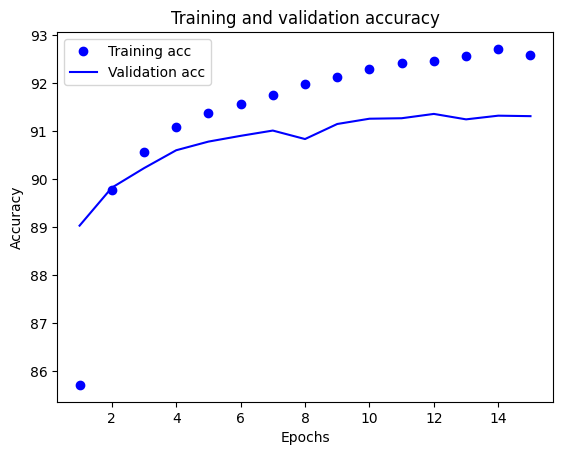

Test loss 0.28, Test accuracy 92.16


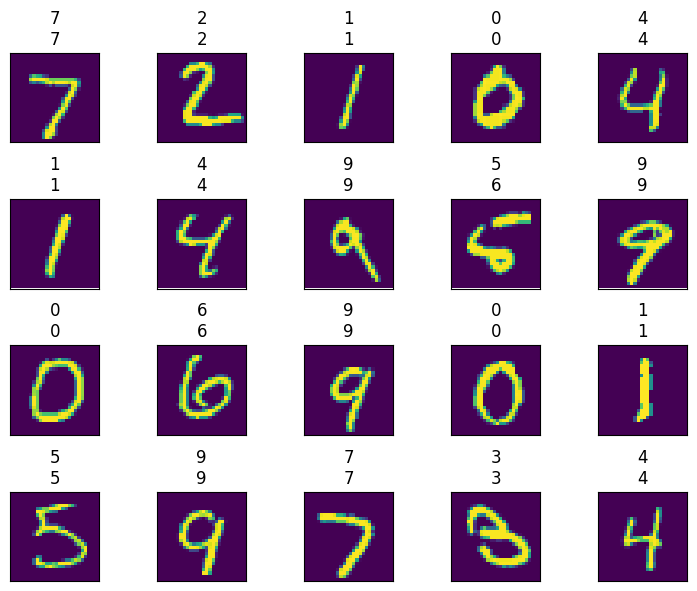

In [2]:
import torchvision
from torchvision import transforms
import torch
import matplotlib.pyplot as plt
from torch import nn

#1.INCARCAREA DATELOR

def load_data_mnist(batch_size, resize=None):

    trans = [transforms.ToTensor()]
    if resize:
        trans.insert(0, transforms.Resize(resize))
    trans = transforms.Compose(trans)
    mnist_train = torchvision.datasets.MNIST(
        root="../data", train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.MNIST(
        root="../data", train=False, transform=trans, download=True)
    mnist_train, mnist_val = torch.utils.data.random_split(mnist_train, [30000, 30000],
                                                           generator=torch.Generator().manual_seed(42))
    return (torch.utils.data.DataLoader(mnist_train, batch_size, shuffle=True,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_val, batch_size, shuffle=False,
                            num_workers=2),
            torch.utils.data.DataLoader(mnist_test, batch_size, shuffle=False,
                            num_workers=2))
batch_size = 100
train_iter, val_iter, test_iter = load_data_mnist(batch_size)

#2.DEFINIREA MODELULUI

net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)) #-> retea neuronala
#28 x 28 pixeli si 10 clase

#setam weight ul pe 1
def init_weights(m):
    if type(m) == nn.Linear:
        m.weight.data.fill_(1) #aici am modificat in cazul in care nu mi da deviatia standard

net.apply(init_weights)

loss = nn.CrossEntropyLoss() #cross entropy loss function

#training

lr = 0.15
optimizer = torch.optim.SGD(net.parameters(), lr=lr)



def evaluate_accuracy(net, data_iter):
    """Compute the accuracy for a model on a dataset."""
    net.eval()  # Set the model to evaluation mode

    total_loss = 0
    total_hits = 0
    total_samples = 0
    with torch.no_grad():
        for X, y in data_iter:
            y_hat = net(X)
            l = loss(y_hat, y)
            total_loss += float(l)
            total_hits += sum(net(X).argmax(axis=1).type(y.dtype) == y)
            total_samples += y.numel()
    return float(total_loss) / len(data_iter), float(total_hits) / total_samples  * 100


def train(net, train_iter, val_iter, loss, num_epochs, optimizer):
    """Train a model."""
    train_loss_all = []
    train_acc_all = []
    val_loss_all = []
    val_acc_all = []
    for epoch in range(num_epochs):
        train_loss, train_acc = train_epoch(net, train_iter, loss, optimizer)
        train_loss_all.append(train_loss)
        train_acc_all.append(train_acc)
        val_loss, val_acc = evaluate_accuracy(net, val_iter)
        val_loss_all.append(val_loss)
        val_acc_all.append(val_acc)
        print(f'Epoch {epoch + 1}, Train loss {train_loss:.2f}, Train accuracy {train_acc:.2f}, Validation loss {val_loss:.2f}, Validation accuracy {val_acc:.2f}')

    return train_loss_all, train_acc_all, val_loss_all, val_acc_all
def train_epoch(net, train_iter, loss, optimizer):
    # Set the model to training mode
    net.train()
    # Sum of training loss, sum of training correct predictions, no. of examples
    total_loss = 0
    total_hits = 0
    total_samples = 0
    for X, y in train_iter:
        # Compute gradients and update parameters
        y_hat = net(X)
        l = loss(y_hat, y)
        # Using PyTorch built-in optimizer & loss criterion
        optimizer.zero_grad()
        l.backward()
        optimizer.step()
        total_loss += float(l)
        total_hits += sum(y_hat.argmax(axis=1).type(y.dtype) == y)
        total_samples += y.numel()
    # Return training loss and training accuracy
    return float(total_loss) / len(train_iter), float(total_hits) / total_samples  * 100
#3.ANTRENAREA PT 15 EPOCHS

num_epochs = 15
train_loss_all, train_acc_all, val_loss_all, val_acc_all = train(net, train_iter, val_iter, loss, num_epochs, optimizer)

#plotting the accuracy

def plot_accuracy(train_acc_all, val_acc_all):
    epochs = range(1, len(train_acc_all) + 1)
    plt.plot(epochs, train_acc_all, 'bo', label='Training acc')
    plt.plot(epochs, val_acc_all, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_accuracy(train_acc_all, val_acc_all)


#classify 20 images

#net ii modelul meu


def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
    """Plot a list of images."""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = plt.subplots(num_rows, num_cols, figsize=figsize)
    plt.tight_layout()
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # Tensor Image
            ax.imshow(img.numpy())
        else:
            # PIL Image
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes
def predict(net, test_iter, n=20):
    """Predict labels."""
    for X, y in test_iter:
        break #se opreste la batch_size imagini(100)

    trues = y[:n] #din cele 100 de imagini selectam doar 20
    # !! aici am modificat

    preds = net(X[:n]).argmax(axis=1) #si asta am modificat o !!

    titles = [str(true.item()) +'\n' + str(pred.item()) for true, pred in zip(trues, preds)]

    show_images(X[:n].reshape((n, 28, 28)), 4, 5, titles=titles)


predict(net, test_iter)


#evaluate the trained model on test set

test_loss, test_acc = evaluate_accuracy(net, test_iter)
print(f'Test loss {test_loss:.2f}, Test accuracy {test_acc:.2f}')
